# PRANAV CAPITAL

## Systematic Multi-Strategy Hedge Fund Simulator

This project builds a simulated £1,000,000 hedge fund from scratch.

The project will investigate how different systematic trading strategies perform individually and how they can be combined into a multi-strategy portfolio.

### Core Pipeline

Market Data → Signals → Positions → Trades → P&L → Risk → Portfolio

In [3]:
print("Welcome to Pranav Capital")

Welcome to Pranav Capital


In [4]:
starting_capital = 1_000_000

print(starting_capital)

1000000


In [5]:
profit = 50_000

ending_capital = starting_capital + profit

print(ending_capital)

1050000


In [6]:
portfolio_return = (ending_capital - starting_capital) / starting_capital

print(portfolio_return)

0.05


In [7]:
print(portfolio_return * 100)

5.0


In [8]:
print(f"The fund made a return of {portfolio_return * 100}%")

The fund made a return of 5.0%


In [9]:
starting_capital = 250_000
ending_capital = 275_000

portfolio_return = (ending_capital - starting_capital) / starting_capital

print(f"Portfolio return: {portfolio_return * 100}%")

Portfolio return: 10.0%


In [10]:
starting_capital = 1_000_000
ending_capital = 900_000

portfolio_return = (ending_capital - starting_capital) / starting_capital

print(f"Portfolio return: {portfolio_return * 100}%")

Portfolio return: -10.0%


## Portfolio Capital and Returns

The fund begins with a fictional £1,000,000 in capital.

Portfolio return measures the percentage change in portfolio value over a period.

The formula is:

Return = (Ending Portfolio Value - Starting Portfolio Value) / Starting Portfolio Value

A positive return indicates a gain, while a negative return indicates a loss.

For example, a portfolio that increases from £1,000,000 to £1,050,000 earns a 5% return.

In [2]:
%pip install yfinance

  Using cached yfinance-1.7.0-py3-none-any.whl.metadata (6.7 kB)
  Using cached multitasking-0.0.13-py3-none-any.whl.metadata (16 kB)
Using cached yfinance-1.7.0-py3-none-any.whl (149 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 11.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 16.1 MB/s  0:00:00 eta 0:00:01
Using cached multitasking-0.0.13-py3-none-any.whl (16 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [yfinance]6/8 [curl_cffi]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /Users/pranavchopra/Desktop/Pranav-Capital/.venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import yfinance as yf

In [4]:
print(yf.__version__)

1.7.0


In [5]:
import sys

print(sys.executable)

/Users/pranavchopra/Desktop/Pranav-Capital/.venv/bin/python


In [6]:
apple = yf.download(
    "AAPL",
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True
)

[*********************100%***********************]  1 of 1 completed


In [7]:
apple.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271553,72.331709,71.029930,71.282583,135480400
2020-01-03,71.568916,72.326882,71.345137,71.501542,146322800
2020-01-06,72.139183,72.177684,70.442784,70.693036,118387200
2020-01-07,71.799934,72.403897,71.580965,72.148835,108872000
2020-01-08,72.954926,73.255706,71.503960,71.503960,132079200


In [8]:
apple.shape

(1508, 5)

In [9]:
apple.columns

MultiIndex([( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])

Matplotlib is building the font cache; this may take a moment.


NameError: name 'plt' is not defined

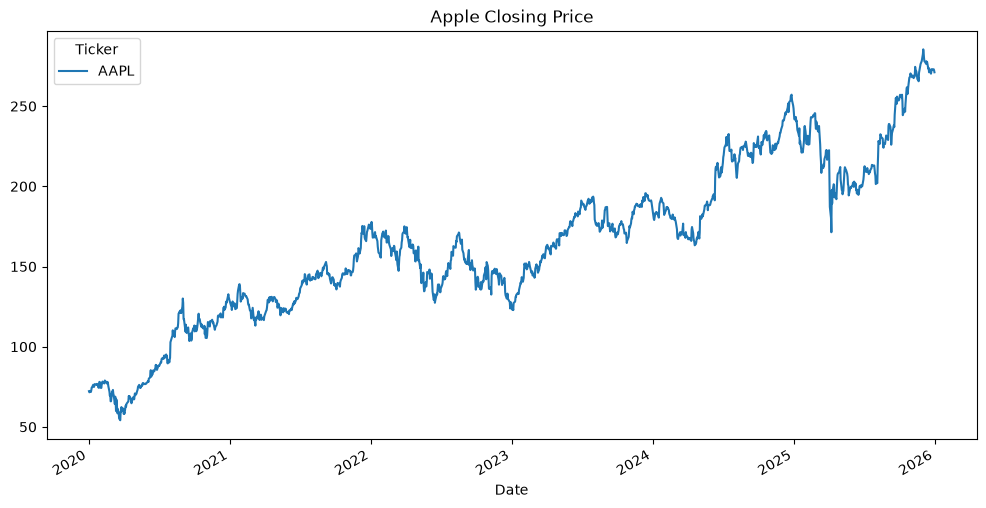

In [10]:
apple["Close"].plot(
    figsize=(12, 6),
    title="Apple Closing Price"
)

plt.ylabel("Price ($)")
plt.show()

In [11]:
import matplotlib.pyplot as plt

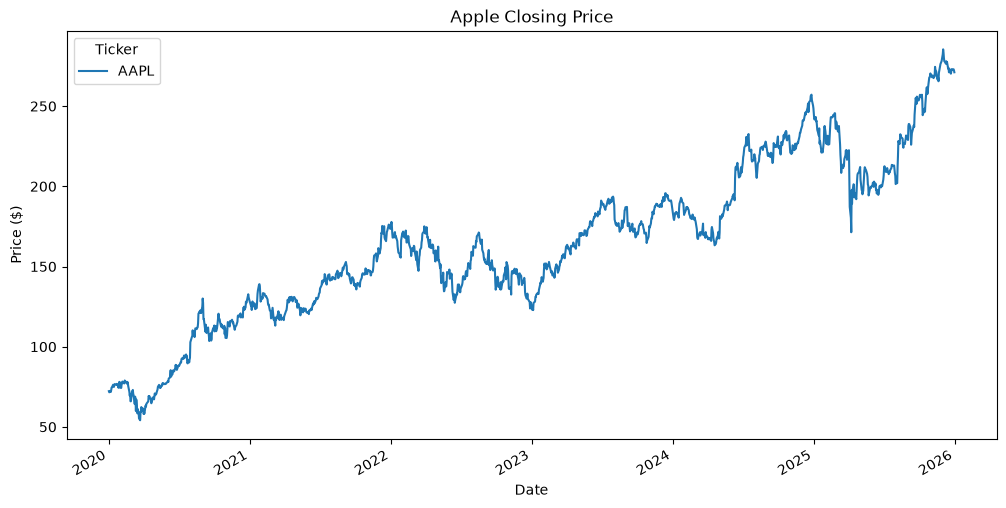

In [12]:
apple["Close"].plot(
    figsize=(12, 6),
    title="Apple Closing Price"
)

plt.ylabel("Price ($)")
plt.show()

In [13]:
apple.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271553,72.331709,71.029930,71.282583,135480400
2020-01-03,71.568916,72.326882,71.345137,71.501542,146322800
2020-01-06,72.139183,72.177684,70.442784,70.693036,118387200
2020-01-07,71.799934,72.403897,71.580965,72.148835,108872000
2020-01-08,72.954926,73.255706,71.503960,71.503960,132079200


In [14]:
print(apple.shape)

(1508, 5)


In [15]:
print(apple.columns)

MultiIndex([( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])


In [16]:
apple["Return"] = apple["Close"].pct_change()

In [17]:
apple[["Close", "Return"]].head(10)

Price,Close,Return
Ticker,AAPL,
Date,,
2020-01-02,72.271553,NaN
2020-01-03,71.568916,-0.009722
2020-01-06,72.139183,0.007968
2020-01-07,71.799934,-0.004703
2020-01-08,72.954926,0.016086
2020-01-09,74.504539,0.021241
2020-01-10,74.672958,0.002261
2020-01-13,76.268311,0.021365


In [18]:
apple = apple.dropna()

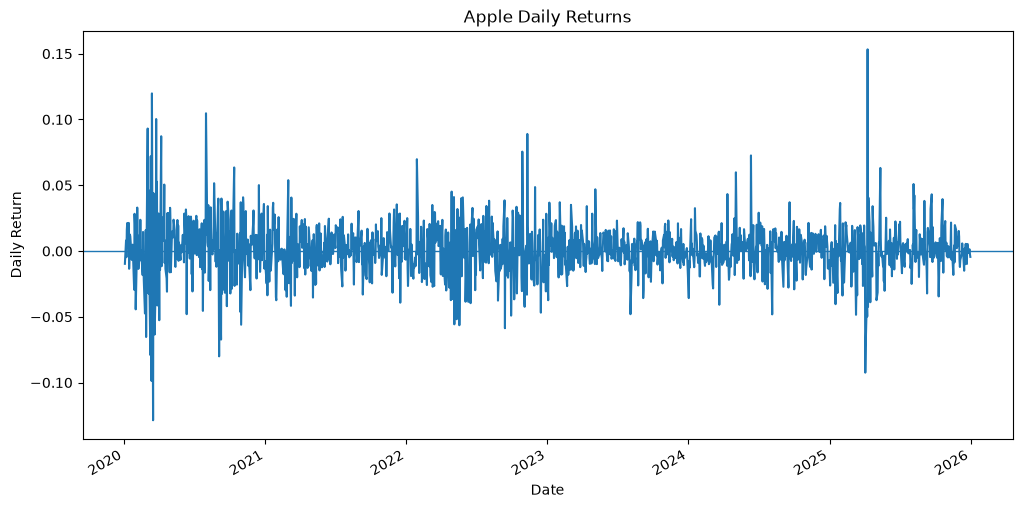

In [19]:
apple["Return"].plot(
    figsize=(12, 6),
    title="Apple Daily Returns"
)

plt.ylabel("Daily Return")
plt.axhline(0, linewidth=1)
plt.show()

In [20]:
print("Average daily return:", apple["Return"].mean())
print("Daily volatility:", apple["Return"].std())
print("Best day:", apple["Return"].max())
print("Worst day:", apple["Return"].min())

Average daily return: 0.0010777333872645978
Daily volatility: 0.020038090268295707
Best day: 0.1532884009024953
Worst day: -0.12864717048314034


In [21]:
apple["Growth"] = (1 + apple["Return"]).cumprod()

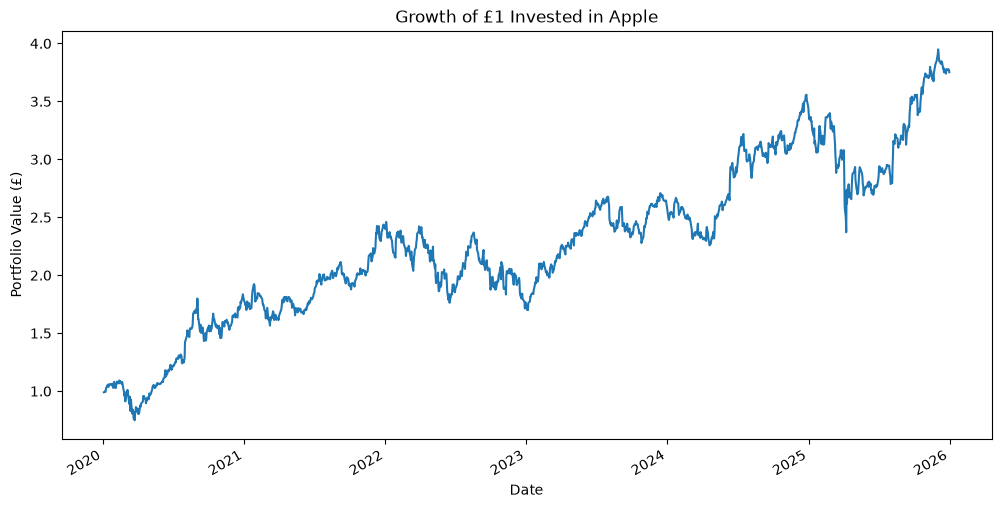

In [22]:
apple["Growth"].plot(
    figsize=(12, 6),
    title="Growth of £1 Invested in Apple"
)

plt.ylabel("Portfolio Value (£)")
plt.show()

In [23]:
apple[["Close", "Return"]].head(10)

Price,Close,Return
Ticker,AAPL,
Date,,
2020-01-03,71.568916,-0.009722
2020-01-06,72.139183,0.007968
2020-01-07,71.799934,-0.004703
2020-01-08,72.954926,0.016086
2020-01-09,74.504539,0.021241
2020-01-10,74.672958,0.002261
2020-01-13,76.268311,0.021365
2020-01-14,75.238441,-0.013503


In [24]:
average_return = apple["Return"].mean()

print("Average daily return:", average_return)

Average daily return: 0.0010777333872645978


In [25]:
volatility = apple["Return"].std()

print("Daily volatility:", volatility)

Daily volatility: 0.020038090268295707


In [26]:
print("Daily volatility:", volatility * 100, "%")

Daily volatility: 2.0038090268295705 %


In [27]:
best_day = apple["Return"].max()
worst_day = apple["Return"].min()

print("Best day:", best_day * 100, "%")
print("Worst day:", worst_day * 100, "%")

Best day: 15.328840090249528 %
Worst day: -12.864717048314034 %


In [28]:
apple["Return"].idxmax()

Timestamp('2025-04-09 00:00:00')

In [29]:
apple["Return"].idxmin()

Timestamp('2020-03-16 00:00:00')

In [30]:
best_date = apple["Return"].idxmax()
worst_date = apple["Return"].idxmin()

print("Best day:", best_date)
print("Worst day:", worst_date)

Best day: 2025-04-09 00:00:00
Worst day: 2020-03-16 00:00:00


In [31]:
apple["Growth"] = (1 + apple["Return"]).cumprod()

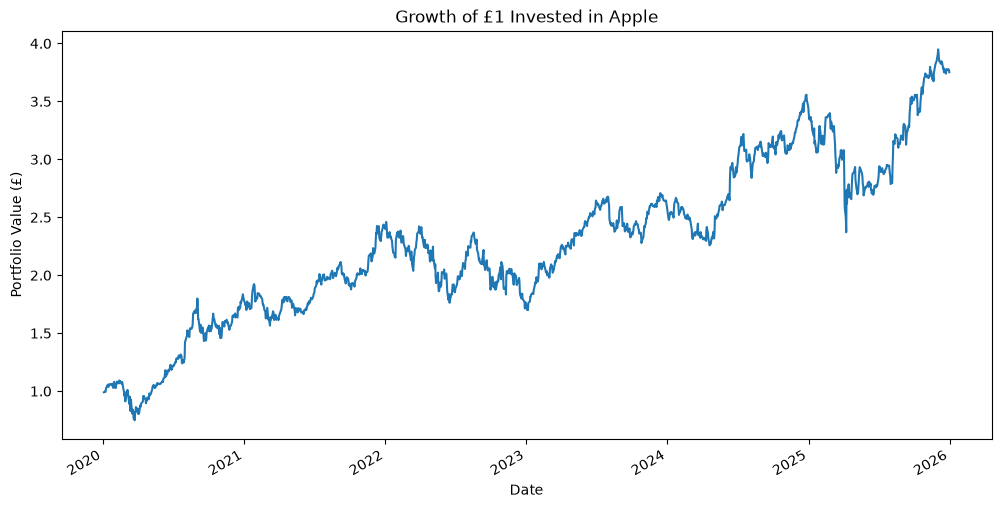

In [32]:
apple["Growth"].plot(
    figsize=(12, 6),
    title="Growth of £1 Invested in Apple"
)

plt.ylabel("Portfolio Value (£)")
plt.show()

In [33]:
total_return = apple["Growth"].iloc[-1] - 1

print("Total return:", total_return * 100, "%")

Total return: 275.1434663773886 %


In [34]:
apple["Growth"].iloc[-1]

np.float64(3.7514346637738862)

In [35]:
starting_capital = 1_000_000

final_capital = starting_capital * apple["Growth"].iloc[-1]

print("Starting capital: £", starting_capital)
print("Final capital: £", round(final_capital, 2))

Starting capital: £ 1000000
Final capital: £ 3751434.66


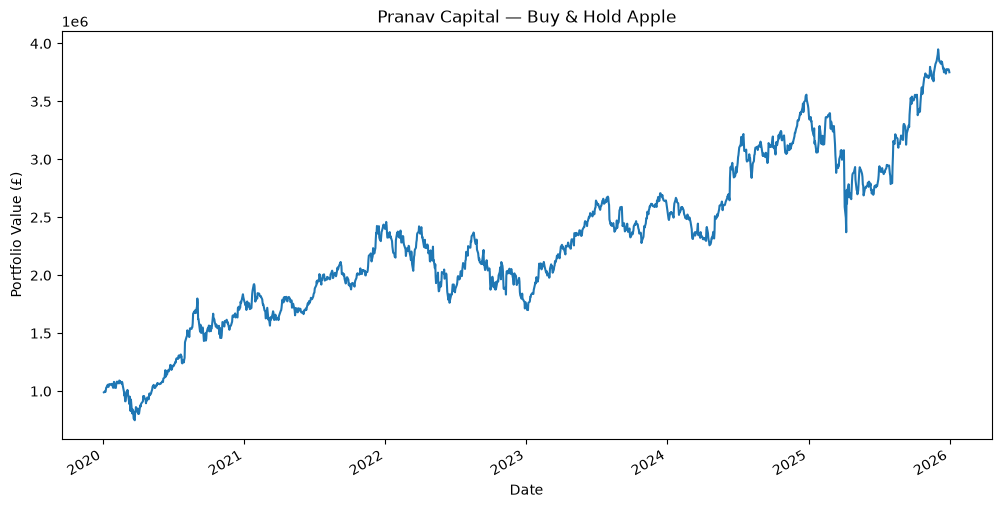

In [36]:
apple["Portfolio_Value"] = starting_capital * apple["Growth"]

apple["Portfolio_Value"].plot(
    figsize=(12, 6),
    title="Pranav Capital — Buy & Hold Apple"
)

plt.ylabel("Portfolio Value (£)")
plt.show()

In [37]:
apple["MA20"] = apple["Close"].rolling(window=20).mean()

In [40]:
apple[["Close", "MA20"]].tail(10)

Price,Close,MA20
Ticker,AAPL,
Date,,
2025-12-17,271.102051,276.209671
2025-12-18,271.451141,276.390680
2025-12-19,272.927124,276.760674
2025-12-22,270.234436,276.734746
2025-12-23,271.620667,276.557228
2025-12-24,273.066711,276.399655
2025-12-26,272.657806,276.192717
2025-12-29,273.016876,275.938908


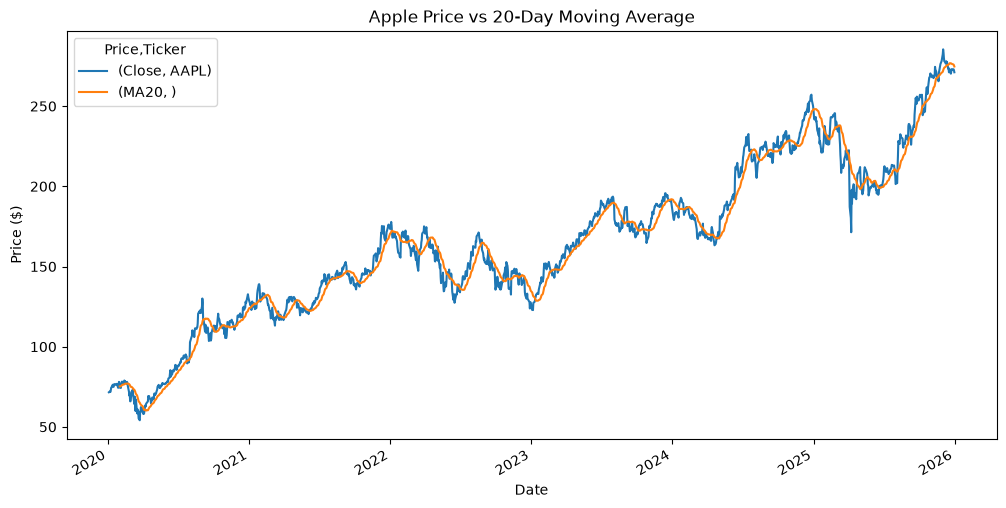

In [41]:
apple[["Close", "MA20"]].plot(
    figsize=(12, 6),
    title="Apple Price vs 20-Day Moving Average"
)

plt.ylabel("Price ($)")
plt.show()

In [44]:
close = apple["Close"].squeeze()
ma20 = apple["MA20"].squeeze()

apple["Signal"] = 0

apple.loc[close > ma20, "Signal"] = 1

In [45]:
apple[["Close", "MA20", "Signal"]].tail(10)

Price,Close,MA20,Signal
Ticker,AAPL,,
Date,,,
2025-12-17,271.102051,276.209671,0
2025-12-18,271.451141,276.390680,0
2025-12-19,272.927124,276.760674,0
2025-12-22,270.234436,276.734746,0
2025-12-23,271.620667,276.557228,0
2025-12-24,273.066711,276.399655,0
2025-12-26,272.657806,276.192717,0
2025-12-29,273.016876,275.938908,0


In [46]:
apple["Signal"].value_counts()

Signal
1    896
0    611
Name: count, dtype: int64

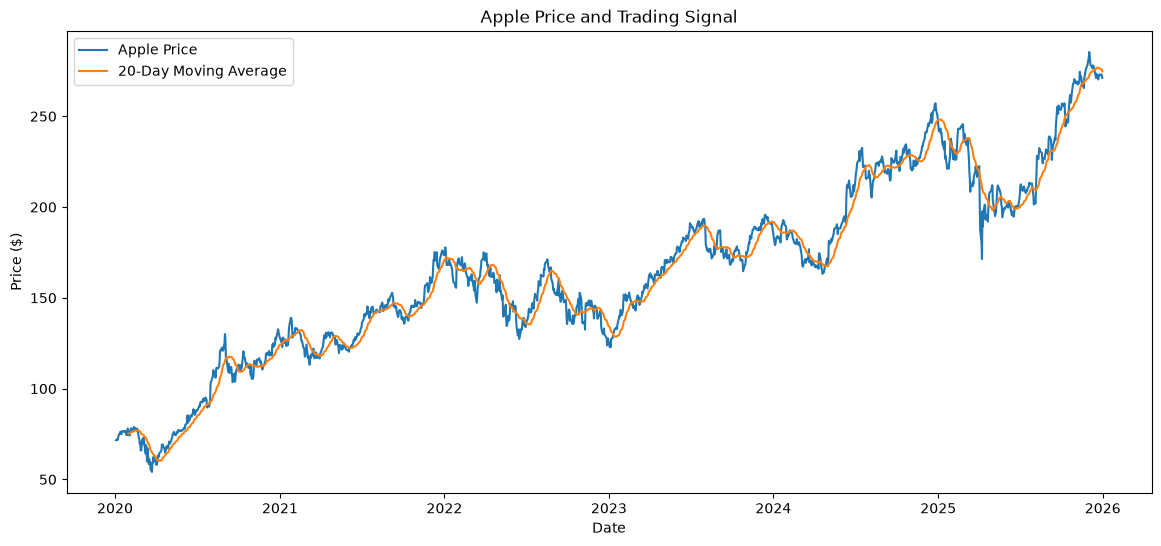

In [47]:
plt.figure(figsize=(14, 6))

plt.plot(apple.index, close, label="Apple Price")
plt.plot(apple.index, ma20, label="20-Day Moving Average")

plt.title("Apple Price and Trading Signal")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()

plt.show()

In [48]:
apple["Position"] = apple["Signal"].shift(1)

In [49]:
apple["Stock_Return"] = apple["Close"].pct_change()

In [50]:
apple["Strategy_Return"] = apple["Position"] * apple["Stock_Return"]

In [51]:
starting_capital = 1_000_000

apple["Portfolio_Value"] = starting_capital * (1 + apple["Strategy_Return"]).cumprod()

In [52]:
apple[["Close", "MA20", "Signal", "Position", "Stock_Return", "Strategy_Return", "Portfolio_Value"]].tail(10)

Price,Close,MA20,Signal,Position,Stock_Return,Strategy_Return,Portfolio_Value
Ticker,AAPL,,,,,,
Date,,,,,,,
2025-12-17,271.102051,276.209671,0,0.0,-0.010087,-0.0,3.399396e+06
2025-12-18,271.451141,276.390680,0,0.0,0.001288,0.0,3.399396e+06
2025-12-19,272.927124,276.760674,0,0.0,0.005437,0.0,3.399396e+06
2025-12-22,270.234436,276.734746,0,0.0,-0.009866,-0.0,3.399396e+06
2025-12-23,271.620667,276.557228,0,0.0,0.005130,0.0,3.399396e+06
2025-12-24,273.066711,276.399655,0,0.0,0.005324,0.0,3.399396e+06
2025-12-26,272.657806,276.192717,0,0.0,-0.001497,-0.0,3.399396e+06
2025-12-29,273.016876,275.938908,0,0.0,0.001317,0.0,3.399396e+06


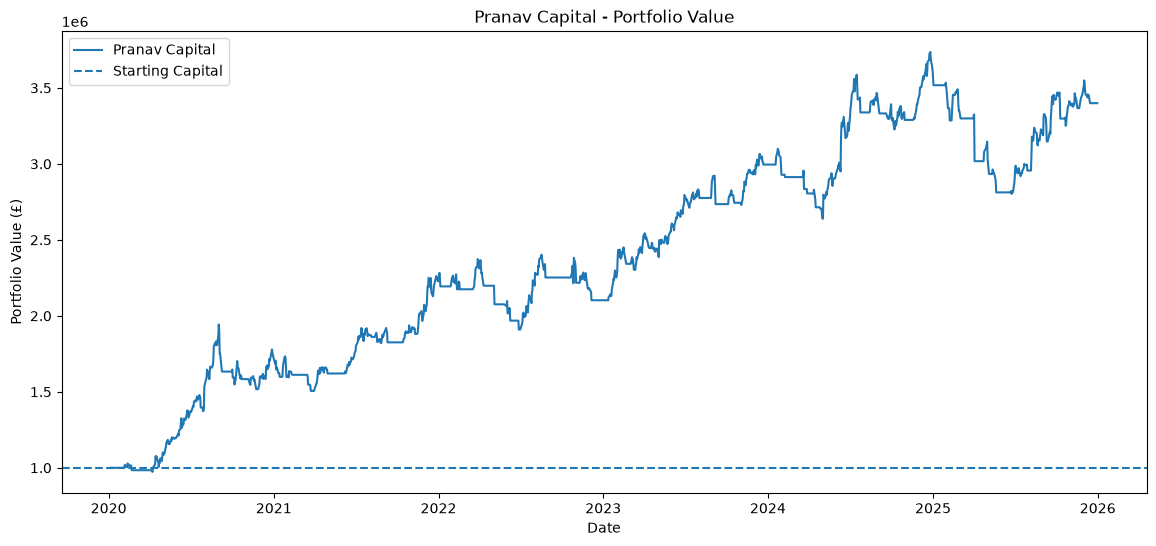

In [53]:
plt.figure(figsize=(14, 6))

plt.plot(
    apple.index,
    apple["Portfolio_Value"],
    label="Pranav Capital"
)

plt.axhline(
    starting_capital,
    linestyle="--",
    label="Starting Capital"
)

plt.title("Pranav Capital - Portfolio Value")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (£)")
plt.legend()

plt.show()

In [54]:
total_return = (
    apple["Portfolio_Value"].iloc[-1] / starting_capital
) - 1

print(f"Total Strategy Return: {total_return:.2%}")

Total Strategy Return: 239.94%


In [55]:
final_value = apple["Portfolio_Value"].iloc[-1]

print(f"Starting Capital: £{starting_capital:,.2f}")
print(f"Final Portfolio Value: £{final_value:,.2f}")
print(f"Total Profit/Loss: £{final_value - starting_capital:,.2f}")

Starting Capital: £1,000,000.00
Final Portfolio Value: £3,399,396.39
Total Profit/Loss: £2,399,396.39


In [56]:
investment_rate = apple["Position"].mean()

print(f"Time invested: {investment_rate:.2%}")

Time invested: 59.50%


In [57]:
days = (apple.index[-1] - apple.index[0]).days

years = days / 365.25

annualised_return = (
    apple["Portfolio_Value"].iloc[-1] / starting_capital
) ** (1 / years) - 1

print(f"Annualised Return: {annualised_return:.2%}")

Annualised Return: 22.65%


In [58]:
annualised_volatility = apple["Strategy_Return"].std() * (252 ** 0.5)

print(f"Annualised Volatility: {annualised_volatility:.2%}")

Annualised Volatility: 20.37%


In [59]:
sharpe_ratio = (
    apple["Strategy_Return"].mean()
    / apple["Strategy_Return"].std()
) * (252 ** 0.5)

print(f"Sharpe Ratio: {sharpe_ratio:.2f}")

Sharpe Ratio: 1.11


In [60]:
running_max = apple["Portfolio_Value"].cummax()

drawdown = (
    apple["Portfolio_Value"] / running_max
) - 1

max_drawdown = drawdown.min()

print(f"Maximum Drawdown: {max_drawdown:.2%}")

Maximum Drawdown: -24.99%


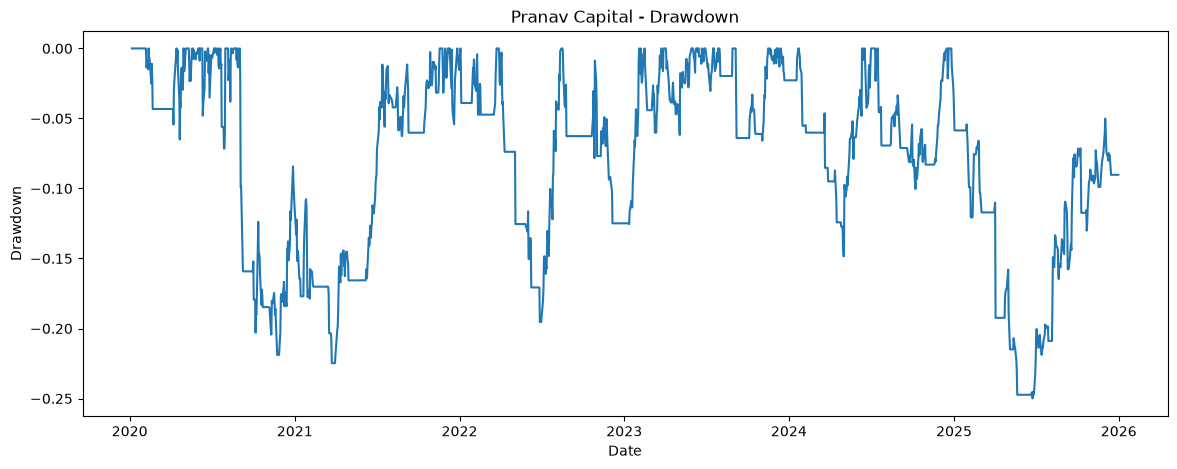

In [61]:
plt.figure(figsize=(14, 5))

plt.plot(
    apple.index,
    drawdown
)

plt.title("Pranav Capital - Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown")

plt.show()

In [62]:
print("====================================")
print("       PRANAV CAPITAL")
print("     STRATEGY PERFORMANCE")
print("====================================")

print(f"Starting Capital:     £{starting_capital:,.0f}")
print(f"Final Portfolio:      £{final_value:,.0f}")
print(f"Total Return:         {total_return:.2%}")
print(f"Annualised Return:    {annualised_return:.2%}")
print(f"Annualised Volatility:{annualised_volatility:.2%}")
print(f"Sharpe Ratio:         {sharpe_ratio:.2f}")
print(f"Maximum Drawdown:     {max_drawdown:.2%}")
print(f"Time Invested:        {investment_rate:.2%}")

print("====================================")

       PRANAV CAPITAL
     STRATEGY PERFORMANCE
Starting Capital:     £1,000,000
Final Portfolio:      £3,399,396
Total Return:         239.94%
Annualised Return:    22.65%
Annualised Volatility:20.37%
Sharpe Ratio:         1.11
Maximum Drawdown:     -24.99%
Time Invested:        59.50%


In [63]:
apple["Buy_Hold_Value"] = (
    starting_capital
    * (apple["Close"] / apple["Close"].iloc[0])
)

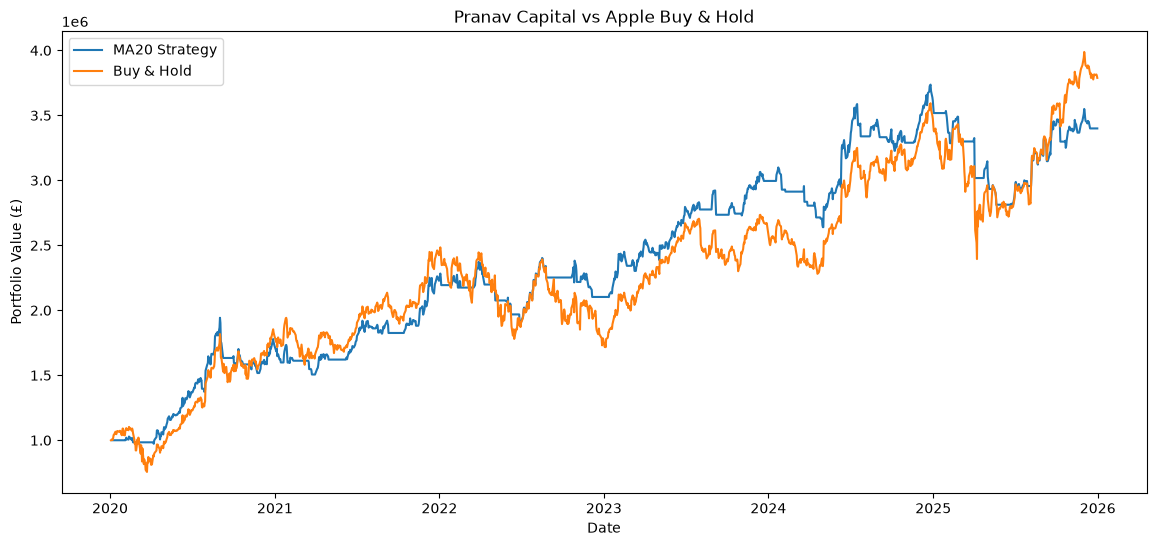

In [64]:
plt.figure(figsize=(14, 6))

plt.plot(
    apple.index,
    apple["Portfolio_Value"],
    label="MA20 Strategy"
)

plt.plot(
    apple.index,
    apple["Buy_Hold_Value"],
    label="Buy & Hold"
)

plt.title("Pranav Capital vs Apple Buy & Hold")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (£)")

plt.legend()

plt.show()

In [65]:
buy_hold_return = (
    apple["Buy_Hold_Value"].iloc[-1] / starting_capital
) - 1

print(f"MA20 Strategy Return: {total_return:.2%}")
print(f"Buy & Hold Return:    {buy_hold_return:.2%}")

MA20 Strategy Return: 239.94%
Buy & Hold Return:    278.83%


In [66]:
close = apple["Close"].squeeze()
ma20 = apple["MA20"].squeeze()

apple["Signal"] = (close > ma20).astype(int)

In [67]:
apple[["Close", "MA20", "Signal"]].tail(10)

Price,Close,MA20,Signal
Ticker,AAPL,,
Date,,,
2025-12-17,271.102051,276.209671,0
2025-12-18,271.451141,276.390680,0
2025-12-19,272.927124,276.760674,0
2025-12-22,270.234436,276.734746,0
2025-12-23,271.620667,276.557228,0
2025-12-24,273.066711,276.399655,0
2025-12-26,272.657806,276.192717,0
2025-12-29,273.016876,275.938908,0


In [68]:
apple["Signal"].value_counts()

Signal
1    896
0    611
Name: count, dtype: int64

In [69]:
apple["Position"] = apple["Signal"].shift(1)

In [70]:
apple["Position"].value_counts()

Position
1.0    896
0.0    610
Name: count, dtype: int64

In [71]:
apple["Market_Return"] = apple["Close"].pct_change()

In [72]:
apple[["Close", "Position", "Market_Return"]].tail(10)

Price,Close,Position,Market_Return
Ticker,AAPL,,
Date,,,
2025-12-17,271.102051,0.0,-0.010087
2025-12-18,271.451141,0.0,0.001288
2025-12-19,272.927124,0.0,0.005437
2025-12-22,270.234436,0.0,-0.009866
2025-12-23,271.620667,0.0,0.005130
2025-12-24,273.066711,0.0,0.005324
2025-12-26,272.657806,0.0,-0.001497
2025-12-29,273.016876,0.0,0.001317


In [73]:
apple["Trade"] = apple["Position"].diff().abs()

In [74]:
apple[["Signal", "Position", "Trade"]].tail(20)

Price,Signal,Position,Trade
Ticker,,,
Date,,,
2025-12-03,1,1.0,0.0
2025-12-04,1,1.0,0.0
2025-12-05,1,1.0,0.0
2025-12-08,1,1.0,0.0
2025-12-09,1,1.0,0.0
2025-12-10,1,1.0,0.0
2025-12-11,1,1.0,0.0
2025-12-12,1,1.0,0.0


In [75]:
number_of_trades = apple["Trade"].sum()

print(f"Number of trades: {number_of_trades:.0f}")

Number of trades: 130


In [76]:
transaction_cost = 0.001

In [77]:
apple["Transaction_Cost"] = apple["Trade"] * transaction_cost

In [78]:
apple[["Position", "Trade", "Transaction_Cost"]].tail(20)

Price,Position,Trade,Transaction_Cost
Ticker,,,
Date,,,
2025-12-03,1.0,0.0,0.000
2025-12-04,1.0,0.0,0.000
2025-12-05,1.0,0.0,0.000
2025-12-08,1.0,0.0,0.000
2025-12-09,1.0,0.0,0.000
2025-12-10,1.0,0.0,0.000
2025-12-11,1.0,0.0,0.000
2025-12-12,1.0,0.0,0.000


In [79]:
apple["Net_Strategy_Return"] = (
    apple["Strategy_Return"]
    - apple["Transaction_Cost"]
)

In [80]:
apple["Net_Portfolio_Value"] = (
    starting_capital
    * (1 + apple["Net_Strategy_Return"]).cumprod()
)

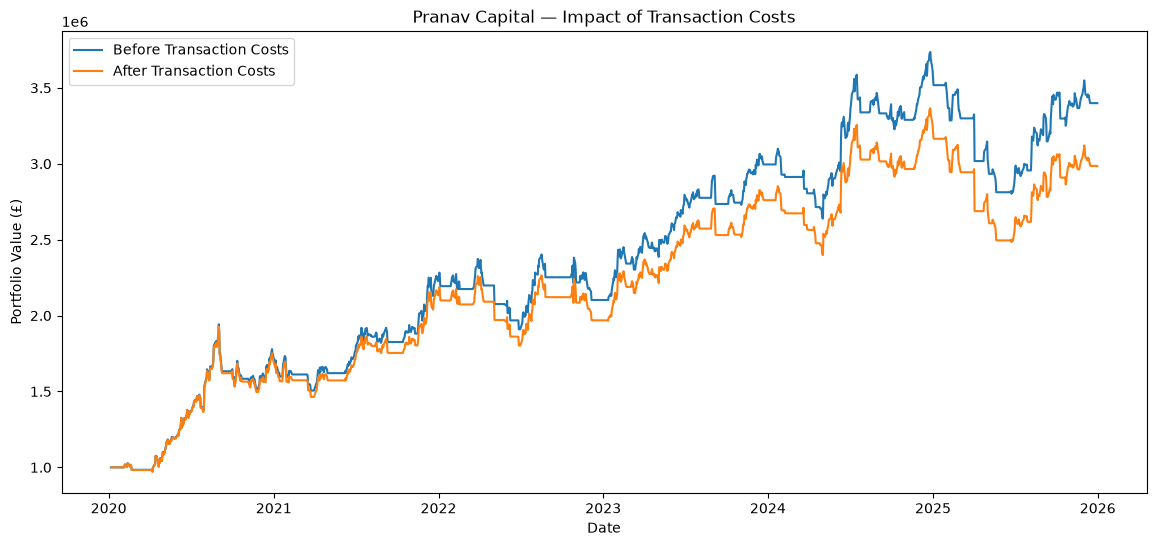

In [81]:
plt.figure(figsize=(14, 6))

plt.plot(
    apple.index,
    apple["Portfolio_Value"],
    label="Before Transaction Costs"
)

plt.plot(
    apple.index,
    apple["Net_Portfolio_Value"],
    label="After Transaction Costs"
)

plt.title("Pranav Capital — Impact of Transaction Costs")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (£)")

plt.legend()

plt.show()

In [82]:
slippage = 0.0005

In [83]:
apple["Trade"]

Date
2020-01-03    NaN
2020-01-06    NaN
2020-01-07    0.0
2020-01-08    0.0
2020-01-09    0.0
             ... 
2025-12-24    0.0
2025-12-26    0.0
2025-12-29    0.0
2025-12-30    0.0
2025-12-31    0.0
Name: Trade, Length: 1507, dtype: float64

In [84]:
apple["Slippage_Cost"] = apple["Trade"] * slippage

In [85]:
apple[["Trade", "Transaction_Cost", "Slippage_Cost"]].tail(20)

Price,Trade,Transaction_Cost,Slippage_Cost
Ticker,,,
Date,,,
2025-12-03,0.0,0.000,0.0000
2025-12-04,0.0,0.000,0.0000
2025-12-05,0.0,0.000,0.0000
2025-12-08,0.0,0.000,0.0000
2025-12-09,0.0,0.000,0.0000
2025-12-10,0.0,0.000,0.0000
2025-12-11,0.0,0.000,0.0000
2025-12-12,0.0,0.000,0.0000


In [86]:
apple["Total_Trading_Cost"] = (
    apple["Transaction_Cost"]
    + apple["Slippage_Cost"]
)

In [87]:
apple[[
    "Trade",
    "Transaction_Cost",
    "Slippage_Cost",
    "Total_Trading_Cost"
]].tail(20)

Price,Trade,Transaction_Cost,Slippage_Cost,Total_Trading_Cost
Ticker,,,,
Date,,,,
2025-12-03,0.0,0.000,0.0000,0.0000
2025-12-04,0.0,0.000,0.0000,0.0000
2025-12-05,0.0,0.000,0.0000,0.0000
2025-12-08,0.0,0.000,0.0000,0.0000
2025-12-09,0.0,0.000,0.0000,0.0000
2025-12-10,0.0,0.000,0.0000,0.0000
2025-12-11,0.0,0.000,0.0000,0.0000
2025-12-12,0.0,0.000,0.0000,0.0000


In [88]:
apple["Net_Strategy_Return"]

Date
2020-01-03    NaN
2020-01-06    NaN
2020-01-07   -0.0
2020-01-08    0.0
2020-01-09    0.0
             ... 
2025-12-24    0.0
2025-12-26   -0.0
2025-12-29    0.0
2025-12-30   -0.0
2025-12-31   -0.0
Name: Net_Strategy_Return, Length: 1507, dtype: float64

In [89]:
apple["Net_Strategy_Return"] = (
    apple["Strategy_Return"]
    - apple["Total_Trading_Cost"]
)

In [90]:
apple["Net_Portfolio_Value"] = (
    starting_capital
    * (1 + apple["Net_Strategy_Return"]).cumprod()
)

In [91]:
plt.figure(figsize=(14, 6))

plt.plot(
    apple.index,
    apple["Strategy_Value"],
    label="Gross Strategy"
)

plt.plot(
    apple.index,
    apple["Net_Portfolio_Value"],
    label="Net Strategy"
)

plt.title("Pranav Capital — Gross vs Net Performance")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (£)")
plt.legend()
plt.show()

KeyError: 'Strategy_Value'

<Figure size 1400x600 with 0 Axes>

In [92]:
apple.columns.tolist()

[('Close', 'AAPL'),
 ('High', 'AAPL'),
 ('Low', 'AAPL'),
 ('Open', 'AAPL'),
 ('Volume', 'AAPL'),
 ('Return', ''),
 ('Growth', ''),
 ('Portfolio_Value', ''),
 ('MA20', ''),
 ('Signal', ''),
 ('Position', ''),
 ('Stock_Return', ''),
 ('Strategy_Return', ''),
 ('Buy_Hold_Value', ''),
 ('Market_Return', ''),
 ('Trade', ''),
 ('Transaction_Cost', ''),
 ('Net_Strategy_Return', ''),
 ('Net_Portfolio_Value', ''),
 ('Slippage_Cost', ''),
 ('Total_Trading_Cost', '')]

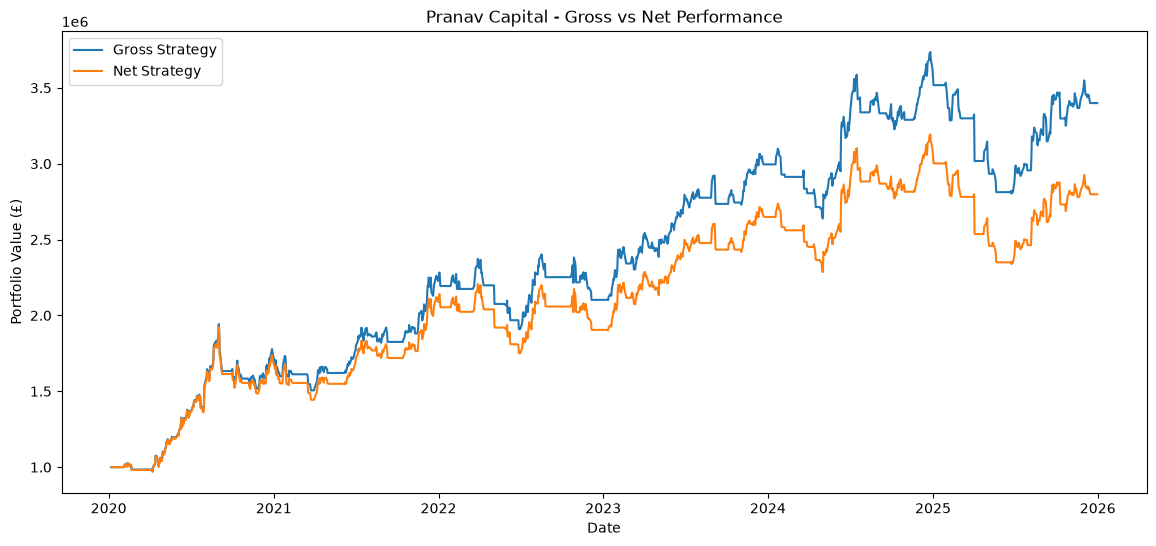

In [93]:
plt.figure(figsize=(14, 6))

plt.plot(
    apple.index,
    apple["Portfolio_Value"],
    label="Gross Strategy"
)

plt.plot(
    apple.index,
    apple["Net_Portfolio_Value"],
    label="Net Strategy"
)

plt.title("Pranav Capital - Gross vs Net Performance")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (£)")
plt.legend()
plt.show()

In [94]:
gross_final_value = apple["Portfolio_Value"].iloc[-1]
net_final_value = apple["Net_Portfolio_Value"].iloc[-1]

gross_profit = gross_final_value - starting_capital
net_profit = net_final_value - starting_capital

print(f"Gross Final Value: £{gross_final_value:,.2f}")
print(f"Net Final Value:   £{net_final_value:,.2f}")
print()
print(f"Gross Profit: £{gross_profit:,.2f}")
print(f"Net Profit:   £{net_profit:,.2f}")

Gross Final Value: £3,399,396.39
Net Final Value:   £2,798,210.12

Gross Profit: £2,399,396.39
Net Profit:   £1,798,210.12


In [95]:
performance_drag = gross_profit - net_profit

print(f"Performance Drag from Trading Costs: £{performance_drag:,.2f}")

Performance Drag from Trading Costs: £601,186.27


In [96]:
windows = [10, 20, 50, 100, 200]

In [97]:
results = []

In [98]:
for window in windows:
    
    ma = apple["Close"].rolling(window=window).mean()
    
    signal = (apple["Close"] > ma).astype(int)
    
    position = signal.shift(1)
    
    strategy_return = position * apple["Market_Return"]
    
    growth = (1 + strategy_return).cumprod()
    
    total_return = growth.iloc[-1] - 1
    
    annualised_return = (
        growth.iloc[-1] ** (1 / years)
    ) - 1
    
    volatility = strategy_return.std() * (252 ** 0.5)
    
    sharpe = annualised_return / volatility
    
    results.append({
        "MA Window": window,
        "Total Return": total_return,
        "Annualised Return": annualised_return,
        "Volatility": volatility,
        "Sharpe": sharpe
    })

In [99]:
results_df = pd.DataFrame(results)

results_df

NameError: name 'pd' is not defined

In [100]:
import pandas as pd

In [101]:
results_df = pd.DataFrame(results)

results_df

,MA Window,Total Return,Annualised Return,Volatility,Sharpe
0,10,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...
1,20,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...
2,50,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...
3,100,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...
4,200,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...


In [102]:
split_index = int(len(apple) * 0.70)

train = apple.iloc[:split_index].copy()
test = apple.iloc[split_index:].copy()

In [103]:
print("Training period:")
print(train.index[0], "→", train.index[-1])

print()

print("Testing period:")
print(test.index[0], "→", test.index[-1])

Training period:
2020-01-03 00:00:00 → 2024-03-12 00:00:00

Testing period:
2024-03-13 00:00:00 → 2025-12-31 00:00:00


In [104]:
train_results = []

windows = [10, 20, 50, 100, 200]

In [105]:
for window in windows:
    
    ma = train["Close"].rolling(window=window).mean()
    
    signal = (train["Close"] > ma).astype(int)
    
    position = signal.shift(1)
    
    strategy_return = position * train["Market_Return"]
    
    growth = (1 + strategy_return).cumprod()
    
    total_return = growth.iloc[-1] - 1
    
    train_years = (
        train.index[-1] - train.index[0]
    ).days / 365.25
    
    annualised_return = (
        growth.iloc[-1] ** (1 / train_years)
    ) - 1
    
    volatility = strategy_return.std() * (252 ** 0.5)
    
    sharpe = annualised_return / volatility
    
    train_results.append({
        "MA Window": window,
        "Total Return": total_return,
        "Annualised Return": annualised_return,
        "Volatility": volatility,
        "Sharpe": sharpe
    })

In [106]:
train_results_df = pd.DataFrame(train_results)

train_results_df

,MA Window,Total Return,Annualised Return,Volatility,Sharpe
0,10,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...
1,20,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...
2,50,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...
3,100,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...
4,200,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...,Ticker AAPL NaN 2020-01-03 00...


In [108]:
train_results = []

windows = [10, 20, 50, 100, 200]

train_close = train["Close"].squeeze()
train_market_return = train["Market_Return"].squeeze()

In [109]:
for window in windows:

    ma = train_close.rolling(window=window).mean()

    signal = (train_close > ma).astype(int)

    position = signal.shift(1)

    strategy_return = position * train_market_return

    growth = (1 + strategy_return).cumprod()

    total_return = growth.iloc[-1] - 1

    train_years = (
        train.index[-1] - train.index[0]
    ).days / 365.25

    annualised_return = (
        growth.iloc[-1] ** (1 / train_years)
    ) - 1

    volatility = strategy_return.std() * (252 ** 0.5)

    sharpe = annualised_return / volatility

    train_results.append({
        "MA Window": window,
        "Total Return": float(total_return),
        "Annualised Return": float(annualised_return),
        "Volatility": float(volatility),
        "Sharpe": float(sharpe)
    })

In [110]:
train_results_df = pd.DataFrame(train_results)

train_results_df

,MA Window,Total Return,Annualised Return,Volatility,Sharpe
0,10,0.996665,0.179480,0.206276,0.870096
1,20,1.913048,0.290778,0.209572,1.387487
2,50,0.815033,0.152928,0.209817,0.728866
3,100,0.623744,0.122680,0.221112,0.554830
4,200,0.242839,0.053269,0.198957,0.267741


In [111]:
best_window = train_results_df.loc[
    train_results_df["Sharpe"].idxmax(),
    "MA Window"
]

print(f"Selected MA Window: {int(best_window)} days")

Selected MA Window: 20 days


In [112]:
best_window = int(best_window)

test_close = test["Close"].squeeze()
test_market_return = test["Market_Return"].squeeze()

test_ma = test_close.rolling(
    window=best_window
).mean()

test_signal = (
    test_close > test_ma
).astype(int)

test_position = test_signal.shift(1)

test_strategy_return = (
    test_position * test_market_return
)

In [113]:
test_growth = (
    1 + test_strategy_return
).cumprod()

In [114]:
test_total_return = test_growth.iloc[-1] - 1

print(f"Out-of-Sample Return: {test_total_return:.2%}")

Out-of-Sample Return: 21.18%


In [115]:
test_strategy_return
test_growth

Date
2024-03-13         NaN
2024-03-14    1.000000
2024-03-15    1.000000
2024-03-18    1.000000
2024-03-19    1.000000
                ...   
2025-12-24    1.211824
2025-12-26    1.211824
2025-12-29    1.211824
2025-12-30    1.211824
2025-12-31    1.211824
Length: 453, dtype: float64

In [116]:
test_years = (
    test.index[-1] - test.index[0]
).days / 365.25

test_annualised_return = (
    test_growth.iloc[-1] ** (1 / test_years)
) - 1

print(f"Out-of-Sample Annualised Return: {test_annualised_return:.2%}")

Out-of-Sample Annualised Return: 11.25%
